# NLP Pipeline: Cairo Restaurant Reviews (Milestone 1)
**Section owner:** Yassin  |  **Input:** the two review JSON files  |  **Output:** `df_reviews` with cleaned text, language, and flags

Design rule: `text_raw` is never modified. Every lossy step writes to a new column, so nothing useful is thrown away automatically.

## 0. Setup
Upload the two review JSON files to Colab (left sidebar > Files > Upload) or mount Drive and change `DATA_DIR`.

In [1]:
!pip -q install emoji

In [2]:
import os, re, json, unicodedata
import pandas as pd

try:
    import emoji
except ImportError:
    emoji = None

DATA_DIR = os.environ.get("DATA_DIR", "/content")
FILES = {
    "Fifth Settlement": "Reviews fifth settlment.json",
    "Rehab/First Settlement": "Rehab_first settlment review.json",
}
KEEP = ["reviewId","placeId","title","text","stars","publishedAtDate",
        "originalLanguage","responseFromOwnerText","textTranslated"]   # reviewer name/ID/photo/URLs are dropped on purpose (privacy)
pd.set_option("display.max_colwidth", 110, "display.width", 250)

## 1. Load and filter
The structural filter keeps only reviews that have written text.

In [3]:
frames = []
for area, fname in FILES.items():
    with open(os.path.join(DATA_DIR, fname), encoding="utf-8") as f:
        d = pd.DataFrame(json.load(f))
    d = d[[c for c in KEEP if c in d.columns]].copy()
    d["area"] = area
    frames.append(d)
df = pd.concat(frames, ignore_index=True)

# Structural filter (team rule)
df_reviews = df[df['text'].notna() & (df['text'].str.strip() != '')].copy()
df_reviews["text_raw"] = df_reviews["text"]          # untouched original
# Some Arabic reviews have an English machine translation appended inside `text`. Cut it off.
AR_L, LA_L = re.compile(r'[\u0600-\u06FF]'), re.compile(r'[A-Za-z]')
def strip_translation(t, tt=None):
    if isinstance(tt, str) and len(tt.strip()) >= 20:
        i = t.find(tt.strip()[:40])
        if i > 0: return t[:i].strip()
    for m in re.finditer(r'\n\s*\n', t):
        head, tail = t[:m.start()], t[m.end():]
        a, l = len(AR_L.findall(head)), len(LA_L.findall(tail))
        if a >= 20 and l >= 40 and len(AR_L.findall(tail)) <= 0.1*l and len(LA_L.findall(head)) <= 0.2*a:
            return head.strip()
    return t
df_reviews["text_src"] = [strip_translation(t, tt) for t, tt in zip(df_reviews["text"], df_reviews["textTranslated"])]
print("Reviews with appended translation removed:", int((df_reviews["text_src"] != df_reviews["text"].str.strip()).sum()))          # untouched original
print(f"Total reviews loaded : {len(df):,}")
print(f"Reviews with text    : {len(df_reviews):,}  ({len(df_reviews)/len(df):.0%})")
print(f"Dropped (no text)    : {len(df)-len(df_reviews):,}")
df_reviews.groupby("area").size()

Reviews with appended translation removed: 7
Total reviews loaded : 6,120
Reviews with text    : 2,855  (47%)
Dropped (no text)    : 3,265


,0
area,
Fifth Settlement,1029
Rehab/First Settlement,1826


In [4]:
# All reviews (with or without text) -> used for ratings/scores
df_all = df.copy()
df_all["has_text"] = df_all["text"].notna() & (df_all["text"].str.strip() != "")

print("Stars missing:", df_all["stars"].isna().sum())
print(df_all["stars"].value_counts().sort_index())

# Average rating per place, from ALL reviews
place_scores = (df_all.groupby("placeId")
                .agg(title=("title", "first"),
                     area=("area", "first"),
                     n_reviews=("stars", "size"),
                     n_with_text=("has_text", "sum"),
                     avg_stars=("stars", "mean"))
                .round(2).reset_index())
place_scores.head()

Stars missing: 0
stars
1     814
2     162
3     348
4     628
5    4168
Name: count, dtype: int64


,placeId,title,area,n_reviews,n_with_text,avg_stars
0,ChIJ-0oRz3M9WBQRO-dvAZ_B19U,أسماك الأندلس,Fifth Settlement,20,7,3.95
1,ChIJ-2tjAwA9WBQRCTQ5piN_Snc,مطعم شامي,Fifth Settlement,20,12,4.50
2,ChIJ-8TGS8EjWBQRIUJXyE9Mg9Y,Mori Sushi - Point 90,Rehab/First Settlement,20,5,4.95
3,ChIJ-TtSp6k9WBQRA20UUHFVOSw,حاتي ابو رويدا,Fifth Settlement,20,10,3.60
4,ChIJ-Y2IR149WBQRABOHG1bnn64,مطعم أسماك البحار,Fifth Settlement,20,9,3.60


## 2. Pipeline operations
| # | Operation | Purpose | Why it fits this dataset |
|---|---|---|---|
| 1 | Noise and owner-reply removal | Remove URLs, phone numbers, odd symbols, extra whitespace; detect reviews that are copies of the owner reply | Reviews come from Google Maps. Owner replies sit in a separate field, so we verify none leaked into `text`. Emojis are kept. |
| 2 | Arabic normalization | Unify alef variants, ى to ي, remove diacritics and tatweel; ة to ه is optional | Egyptian Arabic spelling is inconsistent, which splits one word into many forms |
| 3 | Repeated-letter reduction | Cap letter repeats at 2 (`خطيرررر` to `خطيرر`, `sooooo` to `soo`) and keep a flag | Elongation is emphasis and fragments the vocabulary. The flag keeps the sentiment signal. |
| 4 | Emoji handling | Keep emojis in `text_clean`, add `text_emoji_text` with emojis as words | Emojis carry strong sentiment, so we keep them for models that can use them |
| 5 | Language detection | Label each review `ar`, `en`, `mixed`, `arabizi`, or `other` | The corpus is bilingual, so later models may need per-language handling |

**Deliberately not applied:** stopword removal, stemming, and emoji stripping, because they remove useful sentiment information (for example "not good").

In [5]:
# ---------- Operation 1: noise + owner-reply ----------
URL_RE   = re.compile(r'(https?://\S+|www\.\S+)')
PHONE_RE = re.compile(r'(\+?\d[\d\s\-]{8,}\d)')
EMOJI_RE = re.compile('[\U0001F300-\U0001FAFF\u2600-\u27BF\u2B50\u2B06\u2764]')
CURLY = str.maketrans({'\u2019':"'", '\u2018':"'", '\u201c':'"', '\u201d':'"'})
ALLOWED_PUNCT = set(".,!?;:'\"-()/%&+\u061f\u060c\u061b")

def remove_noise(t):
    t = URL_RE.sub(" ", t)
    t = PHONE_RE.sub(" ", t)
    t = re.sub(r'[\u200b-\u200f\u202a-\u202e\ufe0f]', '', t)          # invisible chars
    t = t.translate(CURLY)                                          # curly quotes -> straight
    t = "".join(ch if (unicodedata.category(ch)[0] in "LNM" or ch.isspace() or ch in ALLOWED_PUNCT
                       or EMOJI_RE.match(ch)) else " " for ch in t)
    return re.sub(r'\s+', ' ', t).strip()

def is_owner_reply_copy(text, reply):
    return bool(isinstance(reply, str) and reply.strip() and text.strip() == reply.strip())

# ---------- Operation 2: Arabic normalization ----------
DIAC_TATWEEL = re.compile(r'[\u064B-\u0652\u0670\u0640]')
def normalize_arabic(t, ta_marbuta=False):
    t = DIAC_TATWEEL.sub('', t)
    t = re.sub('[\u0623\u0625\u0622]', '\u0627', t)    # أ إ آ -> ا
    t = t.replace('\u0649', '\u064a')                    # ى -> ي
    if ta_marbuta:
        t = t.replace('\u0629', '\u0647')                # ة -> ه (lossy, off by default)
    return t

# ---------- Operation 3: repeated letters ----------
REPEAT_RE = re.compile(r'([^\W\d_])\1{2,}')   # used only for the has_elongation flag
def reduce_repeats(t):
    t = re.sub(r'([\u0600-\u06FF])\1{2,}', r'\1', t)    # Arabic: 3+ same letter -> 1
    t = re.sub(r'([A-Za-z])\1{2,}', r'\1\1', t)        # English: 3+ same letter -> 2
    return t
def has_elongation(t):
    return bool(REPEAT_RE.search(t))

# ---------- Operation 4: emoji to text ----------
def emoji_to_text(t):
    if emoji is not None:
        t = emoji.demojize(t, delimiters=(" ", " "))
    else:  # fallback if the library is missing
        t = "".join(f" {unicodedata.name(c,'emoji').lower().replace(' ','_')} " if EMOJI_RE.match(c) else c for c in t)
    return re.sub(r'\s+', ' ', t).strip()

# ---------- Operation 5: language detection ----------
AR_RE, LA_RE = re.compile(r'[\u0600-\u06FF]'), re.compile(r'[A-Za-z]')
ARABIZI_WORDS = {"mesh","msh","kteer","ktir","gamed","gameel","helw","7elw","wallahi","yasta","ya3ny","3ala",
                 "feh","elly","tamam","ezzay","keda","kda","3aref","3shan","3ashan"}
ARABIZI_TOKEN = re.compile(r'^(?:[A-Za-z]+[23567 89][A-Za-z]*|[23567 89][A-Za-z]+)$'.replace(' ',''))
ORDINAL = re.compile(r'^\d+(st|nd|rd|th)$', re.I)
def arabizi_flag(t):
    toks = re.findall(r"[A-Za-z0-9']+", t)
    hits = sum(1 for w in toks if not ORDINAL.match(w)
               and ((len(w) >= 4 and ARABIZI_TOKEN.match(w)) or w.lower() in ARABIZI_WORDS))
    return hits >= 1 and hits / max(len(toks), 1) >= 0.15 and not AR_RE.search(t)

def detect_language(t):
    ar, la = len(AR_RE.findall(t)), len(LA_RE.findall(t))
    other = sum(1 for c in t if c.isalpha() and not AR_RE.match(c) and not LA_RE.match(c))
    if ar + la + other == 0:
        return "none"                      # emoji / digits only
    if other > ar + la:
        return "other"                     # e.g. Chinese
    r = ar / (ar + la)
    if r >= 0.8: return "ar"
    if r <= 0.2: return "arabizi" if arabizi_flag(t) else "en"
    return "mixed"

In [6]:
# ---------- Full pipeline ----------
def clean_text(t, ta_marbuta=False):
    t = remove_noise(t)
    t = normalize_arabic(t, ta_marbuta)
    t = reduce_repeats(t)
    return t

def run_pipeline(df, ta_marbuta=False):
    out = df.copy()
    out["has_elongation"]   = out["text_src"].map(has_elongation)
    out["owner_reply_copy"] = [is_owner_reply_copy(t, r) for t, r in zip(out["text_raw"], out["responseFromOwnerText"])]
    out["text_clean"]       = out["text_src"].map(lambda t: clean_text(t, ta_marbuta))
    out["text_emoji_text"]  = out["text_clean"].map(emoji_to_text)
    out["language"]         = out["text_src"].map(detect_language)
    out["n_words"]          = out["text_clean"].str.split().str.len()
    out["is_duplicate"]     = out.duplicated(subset="text_clean", keep="first")   # flagged, not dropped
    return out

df_reviews = run_pipeline(df_reviews)
df_reviews[["text_raw","text_clean","language","has_elongation"]].head(8)

,text_raw,text_clean,language,has_elongation
1,الأكل ممتاز بس الخدمة سيئة و الويترز تعاملهم سيىء,الاكل ممتاز بس الخدمة سيئة و الويترز تعاملهم سييء,ar,False
2,منتهى قلة الذوق والمعاملة سيئة ووقحة (الشخص اللي\nتعاملت معاه مش الكل)\nلكن الأكل جيد\n\nRude treatment..\...,منتهي قلة الذوق والمعاملة سيئة ووقحة (الشخص اللي تعاملت معاه مش الكل) لكن الاكل جيد,ar,False
3,"I went on three seperate occasions; I've tried their Arabian breakfast which had a lovely spread of fool, ...","I went on three seperate occasions; I've tried their Arabian breakfast which had a lovely spread of fool, ...",en,False
5,مكان رائعةجدا جدا وومتاز وفي،الارجيله من الاخر تعال وجرب وا حتخسر انصح فيه بقوه,مكان رائعةجدا جدا وومتاز وفي،الارجيله من الاخر تعال وجرب وا حتخسر انصح فيه بقوه,ar,False
7,الأكل نوعا ما كويس ومقبول ولكن للأسف الخدمة سيئة جدا والجو العام غير مناسب\nانا متفهمة انه مكان مفتوح وممك...,الاكل نوعا ما كويس ومقبول ولكن للاسف الخدمة سيئة جدا والجو العام غير مناسب انا متفهمة انه مكان مفتوح وممكن...,ar,False
9,خدمه رديئه لاتوجد شبكه هاتف جوال ولا هم عندهم wifi فا انت معزول عن العالم. الأسعار مبالغ فيها والجوده سيئه.,خدمه رديئه لاتوجد شبكه هاتف جوال ولا هم عندهم wifi فا انت معزول عن العالم. الاسعار مبالغ فيها والجوده سيئه.,ar,False
11,"The place has a relaxed, welcoming feel, perfect for hanging out, working, or meeting friends.","The place has a relaxed, welcoming feel, perfect for hanging out, working, or meeting friends.",en,False
12,مرا لذيذ البرقر اخذت كو برقر مزبوط النكهات حرجع له ثاني,مرا لذيذ البرقر اخذت كو برقر مزبوط النكهات حرجع له ثاني,ar,False


## 3. Before / after examples
Real reviews, one per operation. Each row shows the text after every stage so the effect of each step is visible.

In [7]:
def stages(t):
    s1 = remove_noise(t); s2 = normalize_arabic(s1); s3 = reduce_repeats(s2); s4 = emoji_to_text(s3)
    return {"1 raw": t, "2 noise removed": s1, "3 arabic norm": s2, "4 repeats reduced": s3, "5 emoji->text": s4,
            "language": detect_language(t)}

R = df_reviews
def pick(mask, n=1):
    sub = R[mask & (R["n_words"] >= 3)]
    return sub.sample(n, random_state=7).index.tolist() if len(sub) else []

picks = {
 "Op1 noise/symbols": pick(R["text_raw"].str.contains(r'[\u3010\u3011\u2605\u2022\u2026\u2764\u00a0*#~_|]|http|www', regex=True) & (R["language"]!="other")),
 "Op2 Arabic normalization": pick(R["text_raw"].str.contains('[\u064B-\u0652\u0640\u0623\u0625\u0622\u0649]', regex=True) & (R["language"]=="ar")),
 "Op3 elongation (Arabic)": pick(R["has_elongation"] & (R["language"]=="ar")),
 "Op3 elongation (English)": pick(R["has_elongation"] & (R["language"]=="en")),
 "Op4 emoji": pick(R["text_raw"].map(lambda t: bool(EMOJI_RE.search(t))) & (R["language"]=="en")),
 "Op5 mixed ar+en": pick(R["language"]=="mixed"),
 "Op5 arabizi": pick(R["language"]=="arabizi"),
}
rows = []
for name, idx in picks.items():
    for i in idx:
        rows.append({"example": name, **stages(R.loc[i, "text_raw"])})
demo = pd.DataFrame(rows)
for _, r in demo.iterrows():
    print("="*100); print(r["example"], "| language:", r["language"])
    for k in ["1 raw","2 noise removed","3 arabic norm","4 repeats reduced","5 emoji->text"]:
        print(f"  {k:<18}: {r[k][:200]!r}")

Op1 noise/symbols | language: ar
  1 raw             : 'من احلى الاماكن الي اكلت فيها بيتزا في مصر بجد ❤️\nتعامل راقي و سريع جدا في المكان\nو حتى لما طلبتوا عالبيت الدليفري سريع جدا و الاكل سخن جدا 🌸❤️'
  2 noise removed   : 'من احلى الاماكن الي اكلت فيها بيتزا في مصر بجد ❤ تعامل راقي و سريع جدا في المكان و حتى لما طلبتوا عالبيت الدليفري سريع جدا و الاكل سخن جدا 🌸❤'
  3 arabic norm     : 'من احلي الاماكن الي اكلت فيها بيتزا في مصر بجد ❤ تعامل راقي و سريع جدا في المكان و حتي لما طلبتوا عالبيت الدليفري سريع جدا و الاكل سخن جدا 🌸❤'
  4 repeats reduced : 'من احلي الاماكن الي اكلت فيها بيتزا في مصر بجد ❤ تعامل راقي و سريع جدا في المكان و حتي لما طلبتوا عالبيت الدليفري سريع جدا و الاكل سخن جدا 🌸❤'
  5 emoji->text     : 'من احلي الاماكن الي اكلت فيها بيتزا في مصر بجد red_heart تعامل راقي و سريع جدا في المكان و حتي لما طلبتوا عالبيت الدليفري سريع جدا و الاكل سخن جدا cherry_blossom red_heart'
Op2 Arabic normalization | language: ar
  1 raw             : 'أجمل رامين في مصر'
  2 noise removed   :

**How to read the examples**
- *Op1:* symbols, URLs and invisible characters disappear, and emojis stay.
- *Op2:* alef variants, `ى` and diacritics/tatweel are unified, so spelling variants map to one form.
- *Op3:* long repeats shrink to two letters, and `has_elongation` records that emphasis was present.
- *Op4:* emojis are converted to words in a separate column for models that read text only.
- *Op5:* each review gets a language label, and Arabizi is flagged by a heuristic (digits inside Latin words).

In [8]:
# ===== Step 6: weak sentiment labels from stars =====
def star_to_label(s):
    return "negative" if s <= 2 else ("neutral" if s == 3 else "positive")
df_reviews["sentiment"] = df_reviews["stars"].map(star_to_label)
print(df_reviews["sentiment"].value_counts())
print(df_reviews.groupby("sentiment")["n_words"].agg(["mean","median"]).round(1))

# ===== Step 7: model-ready text =====
df_reviews["text_model"] = df_reviews["text_emoji_text"].str.lower()

# ===== Step 8: tokenization =====
TOKEN_RE = re.compile(r"[\u0600-\u06FF]+|[A-Za-z\u00C0-\u024F0-9_']+")
df_reviews["tokens"] = df_reviews["text_model"].map(TOKEN_RE.findall)
df_reviews["n_tokens"] = df_reviews["tokens"].str.len()
from collections import Counter
for lang in ["ar", "en"]:
    c = Counter(t for toks in df_reviews.loc[df_reviews.language == lang, "tokens"] for t in toks)
    print(lang, "vocab:", len(c), "| top 12:", c.most_common(12))

# ===== Step 9: optional stopword-reduced version (TF-IDF only) =====
EN_STOP = set("a an the and or but of to in on at for with is are was were be been am it its this that these those i me my we our you your he she they them their there here as by from so very just also".split())
AR_STOP = set("في من علي الي عن ان انا هو هي هم ده دي دا ديه كان كانت و ف ب ل ك لي لو او ثم كل".split())
KEEP_NEG = set("not no never nor don't didn't doesn't isn't wasn't can't won't dont cant wont مش مو ما لا غير بدون ولا لم لن ليس".split())
STOP = (EN_STOP | AR_STOP) - KEEP_NEG
def to_tfidf_text(tokens, fallback):
    kept = [t for t in tokens if t not in STOP]
    return " ".join(kept) if kept else fallback
df_reviews["text_tfidf"] = [to_tfidf_text(t, m) for t, m in zip(df_reviews["tokens"], df_reviews["text_model"])]

# ===== Step 10: usability flag =====
df_reviews["usable"] = ((df_reviews["n_words"] >= 3) & ~df_reviews["is_duplicate"]
                        & ~df_reviews["language"].isin(["none", "other"]) & ~df_reviews["owner_reply_copy"])
print("Usable reviews:", int(df_reviews["usable"].sum()), "of", len(df_reviews))

# ===== Step 11: provisional split BY PLACE =====
from sklearn.model_selection import GroupShuffleSplit
d = df_reviews[df_reviews["usable"]]
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
tr_idx, tmp_idx = next(gss.split(d, groups=d["placeId"]))
tmp = d.iloc[tmp_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
va_i, te_i = next(gss2.split(tmp, groups=tmp["placeId"]))
df_reviews["split"] = "excluded"
df_reviews.loc[d.index[tr_idx], "split"] = "train"
df_reviews.loc[tmp.index[va_i], "split"] = "val"
df_reviews.loc[tmp.index[te_i], "split"] = "test"
print(pd.crosstab(df_reviews["split"], df_reviews["sentiment"]))
print("Places shared between train and test:",
      len(set(df_reviews.loc[df_reviews.split=="train","placeId"]) & set(df_reviews.loc[df_reviews.split=="test","placeId"])))

sentiment
positive    2037
negative     706
neutral      112
Name: count, dtype: int64
           mean  median
sentiment              
negative   25.4    15.0
neutral    28.5    15.5
positive   14.9     8.0
ar vocab: 6120 | top 12: [('و', 781), ('جدا', 678), ('الاكل', 381), ('في', 365), ('من', 349), ('ممتاز', 190), ('مش', 167), ('المكان', 155), ('جميل', 144), ('علي', 141), ('كان', 134), ('حلو', 125)]
en vocab: 3604 | top 12: [('the', 1728), ('and', 1425), ('was', 715), ('is', 534), ('a', 523), ('food', 515), ('i', 480), ('to', 464), ('service', 364), ('it', 351), ('very', 348), ('good', 322)]
Usable reviews: 2415 of 2855
sentiment  negative  neutral  positive
split                                 
excluded         57       11       372
test            111       23       243
train           431       68      1180
val             107       10       242
Places shared between train and test: 0


In [9]:
needed = ["tokens", "text_model", "usable", "split", "sentiment", "language"]
print([c for c in needed if c not in df_reviews.columns])

[]


In [10]:
# ===== Step 12: single final text column for modeling =====
# text_model (lowercase, emojis as words) + punctuation removed + single spaces.
# Nothing else is removed: no stopwords, no stemming, negations stay.
def make_final(t):
    t = re.sub(r"[^\w\s]|[\u060c\u061b\u061f_]", " ", t.lower())
    return re.sub(r"\s+", " ", t).strip()
df_reviews["text_final"] = df_reviews["text_model"].map(make_final)
df_reviews[["text_raw", "text_final"]].sample(5, random_state=3)

,text_raw,text_final
951,اسوء سندوتش بيوريه كلته في حياتي,اسوء سندوتش بيوريه كلته في حياتي
2213,للأسف تجربة سيئة جدًا أكلنا من المطعم وبعدها تعبنا جامد وظهرت علينا أعراض تسمم كانت تجربة مرعبة ومش هنجرب...,للاسف تجربة سيئة جدا اكلنا من المطعم وبعدها تعبنا جامد وظهرت علينا اعراض تسمم كانت تجربة مرعبة ومش هنجرب ا...
3036,ممتاز,ممتاز
3146,جميل بس المفروض يكون في منيو ب الأسعار,جميل بس المفروض يكون في منيو ب الاسعار
5126,خدمه ممتازه,خدمه ممتازه


## Pipeline v2 ideas (implemented as optional experiments)

This notebook is the first version of the pipeline. The steps below were deliberately kept in separate columns and are not applied automatically, because they are lossy or need experiments. In Milestone 2 we keep only the ones that improve model results.

| # | Idea | What it does | Why it is not in v1 |
|---|---|---|---|
| 1 | Light Arabic stemming | Strips prefixes/suffixes (e.g. النكهات becomes نكه) | Can merge words with different sentiment |
| 2 | Dialect-aware normalization | Maps Egyptian variants to one form (e.g. حلوه to حلو) | Needs a dialect lexicon and manual checks |
| 3 | Arabizi transliteration | Converts Arabizi to Arabic script | Only 9 Arabizi reviews, and the rules are crude |
| 4 | Near-duplicate detection | Flags reviews with very similar text (cosine similarity of character n-grams) | The threshold needs tuning (9 flagged) |
| 5 | Emoji sentiment tags | Replaces emojis with EMO_POS / EMO_NEG / EMO_NEU | We must test whether it beats emoji names |
| 6 | Negation marking | Joins a negation with the next word (مش حلو becomes مش_حلو) | Changes the vocabulary, so it needs an experiment |
| 7 | Class weights | Gives the rare neutral class a higher weight (about 8x) | Belongs to the Milestone 2 experiments |
| 8 | Aspect tagging | Rule-based tags: food, service, price, ambiance, delivery/wait | Rough keyword rules, with no gold annotation yet |
| 9 | Review enrichment | Bayesian average score per place from all 6,120 reviews | Belongs to the recommendation layer |
| 10 | Model-specific tokenization | AraBERT tokenizer | It fragments unsegmented Egyptian text (الاكل becomes الا + ##كل), so Farasa pre-segmentation or a dialect model such as MARBERT should be tested |
| 11 | Glued-word segmentation | Fixes missing spaces (e.g. رائعةجدا, وومتاز) | The pipeline does not repair these yet |

**Principle:** each v2 step will be compared with v1 on the same split and kept only if it improves the metrics.

In [11]:
import numpy as np

# ---------- v2.1 light Arabic stemming (prefix/suffix stripping) ----------
AR_PREFIXES = ["وال", "بال", "كال", "فال", "لل", "ال"]
AR_SUFFIXES = ["ات", "ون", "ين"]
def light_stem(w):
    if not re.match(r'^[\u0600-\u06FF]+$', w):
        return w
    for p in AR_PREFIXES:
        if w.startswith(p) and len(w) - len(p) >= 3:
            w = w[len(p):]; break
    for s in AR_SUFFIXES:
        if w.endswith(s) and len(w) - len(s) >= 3:
            w = w[:-len(s)]; break
    return w
df_reviews["text_stem"] = df_reviews["tokens"].map(lambda ts: " ".join(light_stem(t) for t in ts))

# ---------- v2.2 dialect-aware normalization ----------
DIALECT_MAP = {"دلوقت": "دلوقتي", "كويسه": "كويس", "كويسة": "كويس", "حلوه": "حلو", "حلوة": "حلو",
               "وحشه": "وحش", "وحشة": "وحش", "جامده": "جامد", "جامدة": "جامد",
               "اوي": "جدا", "قوي": "جدا", "خالص": "جدا", "اووي": "جدا"}
df_reviews["text_dialect"] = df_reviews["tokens"].map(lambda ts: " ".join(DIALECT_MAP.get(t, t) for t in ts))

# ---------- v2.3 Arabizi transliteration (rule-based, low confidence) ----------
ARZ_WORDS = {"helw": "حلو", "7elw": "حلو", "kteer": "كتير", "ktir": "كتير", "mesh": "مش", "msh": "مش",
             "gamed": "جامد", "tamam": "تمام", "wallahi": "والله", "gameel": "جميل", "momtaz": "ممتاز",
             "3ala": "على", "3shan": "عشان", "3ashan": "عشان", "awi": "اوي"}
ARZ_CHARS = [("sh", "ش"), ("kh", "خ"), ("gh", "غ"), ("th", "ث"), ("ch", "تش"), ("2", "ء"), ("3", "ع"), ("5", "خ"),
             ("6", "ط"), ("7", "ح"), ("8", "غ"), ("9", "ق"), ("a", "ا"), ("b", "ب"), ("d", "د"), ("f", "ف"),
             ("g", "ج"), ("h", "ه"), ("k", "ك"), ("l", "ل"), ("m", "م"), ("n", "ن"), ("r", "ر"), ("s", "س"),
             ("t", "ت"), ("w", "و"), ("y", "ي"), ("z", "ز"), ("e", ""), ("o", "و"), ("i", "ي"), ("u", "و")]
def arabizi_to_arabic(text):
    out = []
    for w in text.lower().split():
        if w in ARZ_WORDS: out.append(ARZ_WORDS[w]); continue
        if not re.search(r'[a-z]', w): out.append(w); continue
        for lat, ar in ARZ_CHARS: w = w.replace(lat, ar)
        out.append(w)
    return " ".join(out)
mask = df_reviews["language"] == "arabizi"
df_reviews["text_arabizi_ar"] = df_reviews["text_model"]
df_reviews.loc[mask, "text_arabizi_ar"] = df_reviews.loc[mask, "text_model"].map(arabizi_to_arabic)

# ---------- v2.4 near-duplicate detection (char n-gram TF-IDF + cosine) ----------
from sklearn.feature_extraction.text import TfidfVectorizer
u = df_reviews[df_reviews["usable"]]
X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit_transform(u["text_model"])
S = (X @ X.T).toarray()
near = np.triu(S, 1) >= 0.90
df_reviews["is_near_duplicate"] = False
df_reviews.loc[u.index, "is_near_duplicate"] = near.any(axis=0)
print("Near-duplicates flagged:", int(df_reviews["is_near_duplicate"].sum()))

# ---------- v2.5 emoji -> sentiment tags ----------
EMO_POS = set("❤😍😊😋👍👌🥰😁😀🤩🌸🔥💯✨👏🙏😘💕😃😄🤤💖")
EMO_NEG = set("😡😠😤👎🤢🤮😞😢😭💔😒🤬😔😩")
def emoji_to_tag(t):
    return re.sub(r'\s+', ' ', "".join(" EMO_POS " if c in EMO_POS else " EMO_NEG " if c in EMO_NEG
                                        else " EMO_NEU " if EMOJI_RE.match(c) else c for c in t)).strip()
df_reviews["text_emoji_tag"] = df_reviews["text_clean"].map(emoji_to_tag)

# ---------- v2.6 negation marking ----------
NEG_WORDS = set("not no never don't didn't doesn't isn't wasn't can't won't dont cant مش مو ما لا غير ليس لم لن".split())
def mark_negation(tokens):
    out, i = [], 0
    while i < len(tokens):
        if tokens[i] in NEG_WORDS and i + 1 < len(tokens):
            out.append(tokens[i] + "_" + tokens[i + 1]); i += 2
        else:
            out.append(tokens[i]); i += 1
    return " ".join(out)
df_reviews["text_neg"] = df_reviews["tokens"].map(mark_negation)

# ---------- v2.7 class-imbalance: class weights (train split only) ----------
from sklearn.utils.class_weight import compute_class_weight
tr = df_reviews[df_reviews["split"] == "train"]
classes = np.array(["negative", "neutral", "positive"])
w = compute_class_weight("balanced", classes=classes, y=tr["sentiment"])
CLASS_WEIGHTS = {str(c): float(round(x, 2)) for c, x in zip(classes, w)}
print("Class weights:", CLASS_WEIGHTS)

# ---------- v2.8 rule-based aspect tagging ----------
ASPECTS = {
 "food": "اكل الاكل طعم بيتزا برجر لذيذ طازج شاورما سمك food taste pizza burger delicious fresh chicken meal dish".split(),
 "service": "خدمة الخدمة موظف الموظفين تعامل ويتر service staff waiter waitress rude friendly manager".split(),
 "price": "سعر اسعار الاسعار غالي رخيص مكلف price prices expensive cheap value overpriced".split(),
 "ambiance": "مكان جو ديكور هادي نضيف نظافة ambiance atmosphere clean decor music noisy cozy place".split(),
 "delivery_wait": "توصيل دليفري انتظار بطيء متاخر delivery wait waiting slow late fast order".split(),
}
def tag_aspects(tokens):
    stems = set(tokens) | {light_stem(t) for t in tokens}
    return [a for a, words in ASPECTS.items() if stems & set(words)]
df_reviews["aspects"] = df_reviews["tokens"].map(tag_aspects)
print(df_reviews["aspects"].explode().value_counts(dropna=False))

# ---------- v2.9 review enrichment: Bayesian average per place (ALL reviews) ----------
C = df["stars"].mean()          # global mean from all 6,120 reviews
M = 10                          # prior strength
g = df.groupby("placeId")["stars"].agg(["count", "mean"])
g["bayes_score"] = ((g["count"] * g["mean"] + M * C) / (g["count"] + M)).round(2)
place_rank = g.join(df.groupby("placeId")["title"].first()).sort_values("bayes_score", ascending=False)
place_rank.head(10)

# ---------- v2.10 model-specific tokenization (needs internet in Colab) ----------
try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("aubmindlab/bert-base-arabertv2")
    for t in df_reviews.loc[df_reviews.language == "ar", "text_clean"].head(3):
        print(t[:60], "->", tok.tokenize(t)[:12])
except Exception as e:
    print("Skipped (install transformers / no internet):", type(e).__name__)

Near-duplicates flagged: 9
Class weights: {'negative': 1.3, 'neutral': 8.23, 'positive': 0.47}
aspects
food             1285
NaN              1018
service           759
ambiance          536
price             194
delivery_wait     166
Name: count, dtype: int64


config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/611 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/720k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

الاكل ممتاز بس الخدمة سيئة و الويترز تعاملهم سييء -> ['الا', '##كل', 'ممتاز', 'بس', 'الخد', '##مة', 'سيئ', '##ة', 'و', 'الوي', '##ترز', 'تعامل']
منتهي قلة الذوق والمعاملة سيئة ووقحة (الشخص اللي تعاملت معاه -> ['منتهي', 'قل', '##ة', 'الذ', '##وق', 'والم', '##عام', '##لة', 'سيئ', '##ة', 'وو', '##ق']
مكان رائعةجدا جدا وومتاز وفي،الارجيله من الاخر تعال وجرب وا  -> ['مكان', 'رائع', '##ة', '##جدا', 'جدا', 'وو', '##مت', '##از', 'وفي', '،', 'الا', '##رجي']


All reviews              6120
No written text          3265
With written text        2855
Duplicate texts           161
Very short (<3 words)     424
Usable for modeling      2415


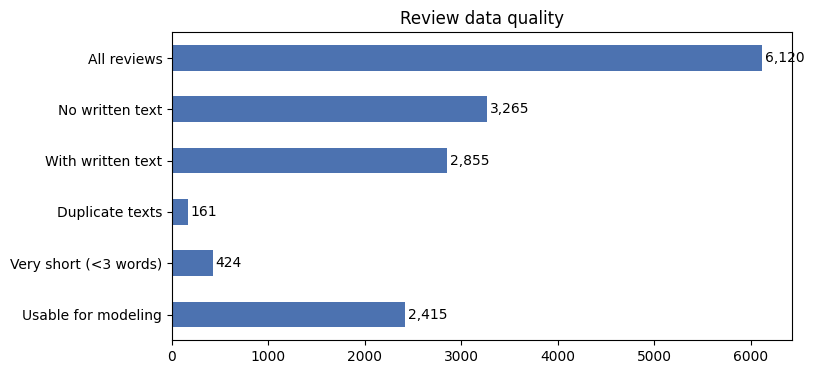

In [15]:
import matplotlib.pyplot as plt
has_text = df["text"].notna() & (df["text"].str.strip() != "")
quality = pd.Series({
    "All reviews": len(df),
    "No written text": int((~has_text).sum()),
    "With written text": len(df_reviews),
    "Duplicate texts": int(df_reviews["is_duplicate"].sum()),
    "Very short (<3 words)": int((df_reviews["n_words"] < 3).sum()),
    "Usable for modeling": int(df_reviews["usable"].sum()),
})
print(quality.to_string())
ax = quality.plot(kind="barh", figsize=(8, 4), color="#4c72b0")
for i, v in enumerate(quality): ax.text(v + 30, i, f"{v:,}", va="center")
plt.title("Review data quality"); plt.gca().invert_yaxis(); plt.show()

       n_chars  n_words  n_tokens
count   2855.0   2855.0    2855.0
mean     100.9     18.1      18.2
std      150.4     25.8      26.0
min        1.0      1.0       0.0
25%       23.0      4.0       4.0
50%       54.0     10.0      10.0
75%      117.0     21.0      21.0
max     2709.0    464.0     475.0


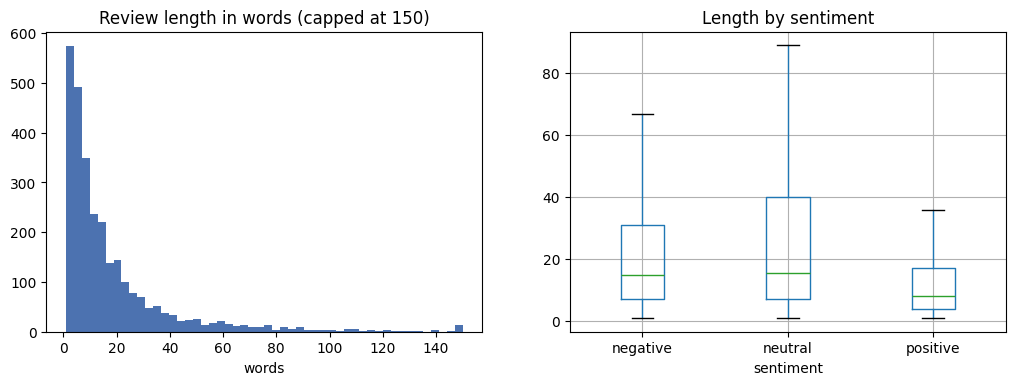

In [16]:
df_reviews["n_chars"] = df_reviews["text_raw"].str.len()
print(df_reviews[["n_chars", "n_words", "n_tokens"]].describe().round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df_reviews["n_words"].clip(upper=150), bins=50, color="#4c72b0")
ax[0].set_title("Review length in words (capped at 150)"); ax[0].set_xlabel("words")
df_reviews.boxplot(column="n_words", by="sentiment", ax=ax[1], showfliers=False)
ax[1].set_title("Length by sentiment"); plt.suptitle(""); plt.show()

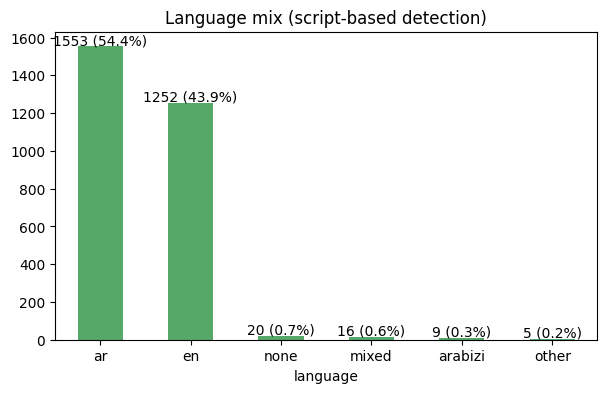

Reviews with emoji: 0.132
Share with elongated letters, by language:
language
ar         0.055
arabizi    0.444
en         0.025
mixed      0.062
none       0.000
other      0.200


In [17]:
lang = df_reviews["language"].value_counts()
ax = lang.plot(kind="bar", figsize=(7, 4), color="#55a868")
for i, v in enumerate(lang): ax.text(i, v + 10, f"{v} ({v/len(df_reviews):.1%})", ha="center")
plt.title("Language mix (script-based detection)"); plt.xticks(rotation=0); plt.show()
print("Reviews with emoji:", round(df_reviews["text_raw"].map(lambda t: bool(EMOJI_RE.search(t))).mean(), 3))
print("Share with elongated letters, by language:")
print(df_reviews.groupby("language")["has_elongation"].mean().round(3).to_string())

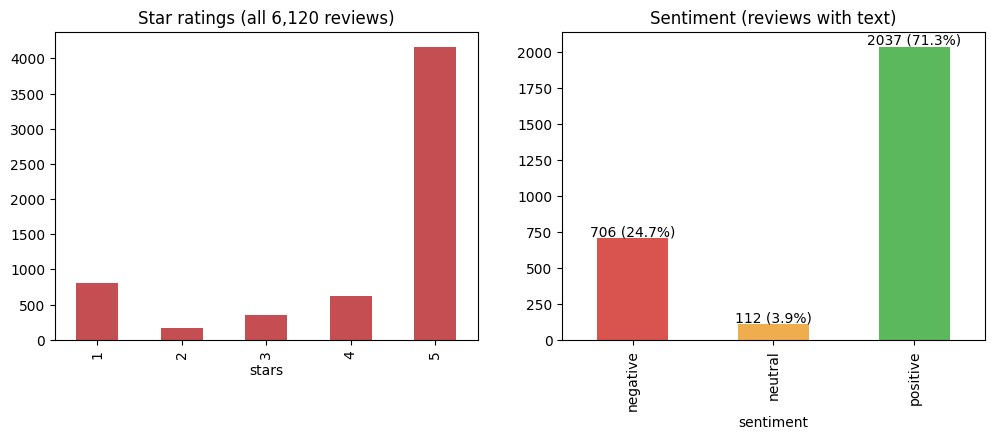

Positive : neutral imbalance = 18.2 : 1
Share of reviews that include text, by star rating:
stars
1    0.75
2    0.58
3    0.32
4    0.26
5    0.45


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
stars = df["stars"].value_counts().sort_index()
stars.plot(kind="bar", ax=ax[0], color="#c44e52"); ax[0].set_title("Star ratings (all 6,120 reviews)")
order = ["negative", "neutral", "positive"]
sent = df_reviews["sentiment"].value_counts().reindex(order)
sent.plot(kind="bar", ax=ax[1], color=["#d9534f", "#f0ad4e", "#5cb85c"]); ax[1].set_title("Sentiment (reviews with text)")
for i, v in enumerate(sent): ax[1].text(i, v + 15, f"{v} ({v/len(df_reviews):.1%})", ha="center")
plt.show()
print("Positive : neutral imbalance =", round(sent["positive"] / sent["neutral"], 1), ": 1")
print("Share of reviews that include text, by star rating:")
print(df.assign(has_text=has_text).groupby("stars")["has_text"].mean().round(2).to_string())

In [19]:
for s in ["negative", "neutral", "positive"]:
    print("=" * 40, s.upper())
    sample = df_reviews[(df_reviews["sentiment"] == s) & (df_reviews["n_words"].between(6, 25))]
    for t in sample.sample(3, random_state=1)["text_raw"]:
        print(" -", t[:160].replace("\n", " "))

======================================== NEGATIVE
 - Overpriced, small portions, weird vibes. We have to pay 100 egp to park in an empty land. Ridiculous
 - Very poor quality and tasteless with unprofessional service.
 - خدمة بطيئة جدا  الكراسي والترابيزات مافيش نظافة
======================================== NEUTRAL
 - Comfortable place and Good staff specific Bogi
 - كان هيبقي ٥ نجوم لو خدمه العملاء تكون متعاونه لان الواحد لما يطلب ويرن فوق الساعتين دا حقيقي مينفعش
 - the food is a solid 6
======================================== POSITIVE
 - Good Prices. Friendly Staff. Clean Place
 - المكان تحفههه و الأكل جمييلللل فرع الجامعه
 - الاكل جميل جدا وموظف الصالة راجل محترم


## 4. Pipeline summary statistics

In [12]:
print("Language distribution:"); print(R["language"].value_counts().to_frame("reviews").assign(share=lambda x: (x.reviews/len(R)).round(3)))
print("\nOwner-reply copies found in review text :", int(R["owner_reply_copy"].sum()))
print("Reviews with elongation                 :", int(R["has_elongation"].sum()))
print("Reviews containing emoji                :", int(R["text_raw"].map(lambda t: bool(EMOJI_RE.search(t))).sum()))
print("Changed by cleaning (text_clean != raw) :", int((R["text_clean"] != R["text_raw"]).sum()))
print("Very short (<3 words)                   :", int((R["n_words"] < 3).sum()), "(flagged, not removed)")
print("Duplicate cleaned texts (flagged)       :", int(R["is_duplicate"].sum()))

Language distribution:
          reviews  share
language                
ar           1553  0.544
en           1252  0.439
none           20  0.007
mixed          16  0.006
arabizi         9  0.003
other           5  0.002

Owner-reply copies found in review text : 0
Reviews with elongation                 : 122
Reviews containing emoji                : 376
Changed by cleaning (text_clean != raw) : 1236
Very short (<3 words)                   : 424 (flagged, not removed)
Duplicate cleaned texts (flagged)       : 161


In [13]:
# Save for teammates (no reviewer identity columns)
cols = ["reviewId","placeId","title","area","stars","publishedAtDate","sentiment",
        "text_raw","text_clean","text_emoji_text","text_model","text_final","text_tfidf",
        "language","has_elongation","n_words","n_tokens","is_duplicate","is_near_duplicate","usable","split"]
out_path = os.path.join(DATA_DIR, "reviews_clean.csv")
df_reviews[cols].to_csv(out_path, index=False, encoding="utf-8-sig")
print("saved", out_path, "| rows:", len(df_reviews))
try:
    from google.colab import files
    files.download(out_path)
except ImportError:
    pass

saved /content/reviews_clean.csv | rows: 2855


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
r = df_reviews[df_reviews["text_raw"].str.contains("متفهمة انه مكان مفتوح", na=False)].iloc[0]
print(r["text_final"])

الاكل نوعا ما كويس ومقبول ولكن للاسف الخدمة سيئة جدا والجو العام غير مناسب انا متفهمة انه مكان مفتوح وممكن اي زبون يدخن ولكن للاسف الكافيه طماع وهاد السبب بخلي الطاولات كتير قريبين علي بعض فهو بتحس حالك انت واللي جمبك قاعدين مع بعض بالتالي ازا في شخص بدخن فانت للاسف حتكون المتضرر الاكبر فلا يستحق الزيارة بتاتا
